# NEPAL FLOOD & WEATHER ANALYSIS

## Part 1: River Discharge Prediction

Predicting tomorrow's river discharge (in m³/s) from today's weather and river data.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df =pd.read_csv('/content/Nepal_Flood_Weather_Analysis.csv')

In [ ]:
df.head()

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,rain_mm,temperature_mean_c,dew_point_mean_c,precipitation_hours,relative_humidity_mean_pct,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s
0,2023-01-01 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,12.2,-2.6,0,37,13.9,68.0,187,0.22
1,2023-01-02 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,11.1,-4.8,0,34,13.4,69.8,191,0.21
2,2023-01-03 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,11.5,-10.3,0,22,14.5,72.0,183,0.21
3,2023-01-04 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,9.6,-8.9,0,29,11.2,67.7,187,0.20
4,2023-01-05 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,10.1,-10.2,0,26,7.4,69.8,54,0.20


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13390 entries, 0 to 13389
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   date                         13390 non-null  object 
 1   location                     13390 non-null  object 
 2   river                        13390 non-null  object 
 3   basin                        13390 non-null  object 
 4   dhm_station                  13390 non-null  float64
 5   latitude                     13390 non-null  float64
 6   longitude                    13390 non-null  float64
 7   elevation_m                  13390 non-null  int64  
 8   precipitation_mm             13390 non-null  float64
 9   soil_moisture_0_100cm_m3m3   13390 non-null  float64
 10  rain_mm                      13390 non-null  float64
 11  temperature_mean_c           13390 non-null  float64
 12  dew_point_mean_c             13390 non-null  float64
 13  precipitation_ho

In [ ]:
print("Numerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(include="object").columns.tolist())

Numerical columns:
['dhm_station', 'latitude', 'longitude', 'elevation_m', 'precipitation_mm', 'soil_moisture_0_100cm_m3m3', 'rain_mm', 'temperature_mean_c', 'dew_point_mean_c', 'precipitation_hours', 'relative_humidity_mean_pct', 'wind_speed_max_kmh', 'wind_gusts_max_kmh', 'wind_direction_dominant_deg', 'river_discharge_m3s']

Categorical columns:
['date', 'location', 'river', 'basin']


In [ ]:
df.isna().sum()

,0
date,0
location,0
river,0
basin,0
dhm_station,0
latitude,0
longitude,0
elevation_m,0
precipitation_mm,0
soil_moisture_0_100cm_m3m3,0


In [ ]:
print("total missing values=",df.isna().sum().sum())

total missing values= 0


In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
13385,False
13386,False
13387,False
13388,False


In [ ]:
print("total duplicates =",df.duplicated().sum())

total duplicates = 0


In [ ]:
df['river_discharge_m3s'].describe()

,river_discharge_m3s
count,13390.000000
mean,20.372064
std,84.333629
min,0.000000
25%,0.260000
50%,1.880000
75%,10.530000
max,3175.870000


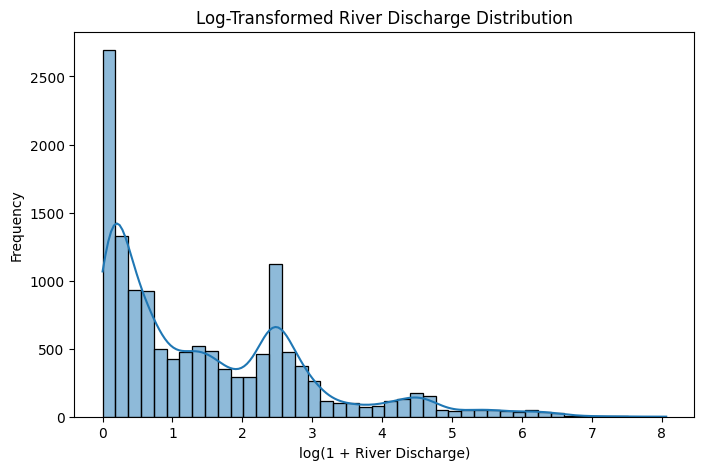

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(np.log1p(df["river_discharge_m3s"]), kde=True)

plt.title("Log-Transformed River Discharge Distribution")
plt.xlabel("log(1 + River Discharge)")
plt.ylabel("Frequency")

plt.show()

In [ ]:
df.groupby("location")["river_discharge_m3s"].mean().sort_values(ascending=False)

,river_discharge_m3s
location,
Kusum,125.812158
Belsot,33.032636
Chameliya/Nayalbadi,31.393465
Bahrabise,5.051314
Devghat,2.331277
Khokana,1.658006
Chatara,1.491344
Rasuwagadhi,1.406751
Chisapani,0.847072


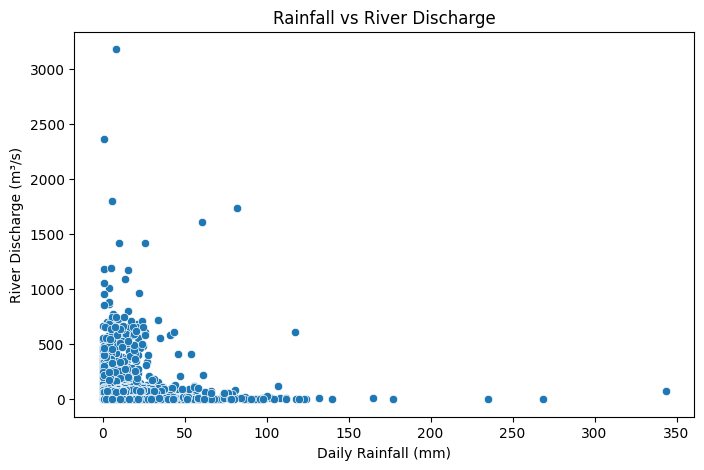

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="rain_mm",
    y="river_discharge_m3s"
)

plt.title("Rainfall vs River Discharge")
plt.xlabel("Daily Rainfall (mm)")
plt.ylabel("River Discharge (m³/s)")
plt.show()

In [ ]:
corr = df.select_dtypes(include=np.number).corr()

corr["river_discharge_m3s"].sort_values(ascending=False)

,river_discharge_m3s
river_discharge_m3s,1.000000
dew_point_mean_c,0.226308
temperature_mean_c,0.178499
relative_humidity_mean_pct,0.171687
soil_moisture_0_100cm_m3m3,0.151942
precipitation_hours,0.145097
rain_mm,0.099743
precipitation_mm,0.098626
wind_speed_max_kmh,0.051560
latitude,0.031714


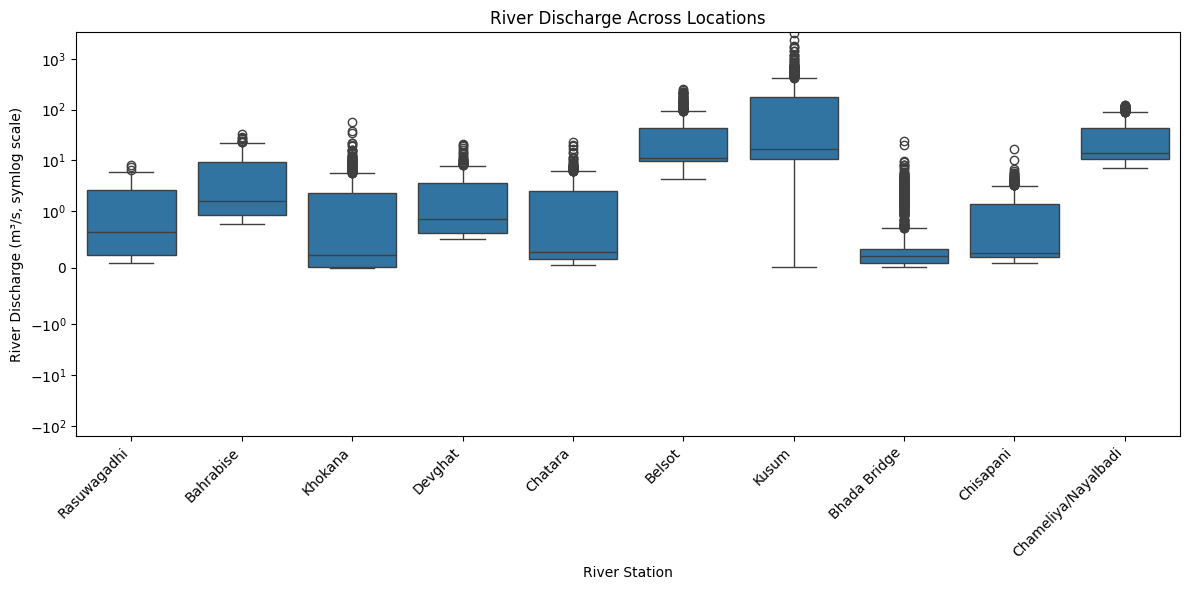

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="location",
    y="river_discharge_m3s"
)

plt.yscale("symlog", linthresh=1)
plt.xticks(rotation=45, ha="right")
plt.title("River Discharge Across Locations")
plt.xlabel("River Station")
plt.ylabel("River Discharge (m³/s, symlog scale)")
plt.tight_layout()
plt.show()

In [ ]:
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

dhm_station: 0 outliers
latitude: 1339 outliers
longitude: 0 outliers
elevation_m: 0 outliers
precipitation_mm: 1860 outliers
soil_moisture_0_100cm_m3m3: 23 outliers
rain_mm: 1915 outliers
temperature_mean_c: 0 outliers
dew_point_mean_c: 71 outliers
precipitation_hours: 345 outliers
relative_humidity_mean_pct: 96 outliers
wind_speed_max_kmh: 522 outliers
wind_gusts_max_kmh: 832 outliers
wind_direction_dominant_deg: 0 outliers
river_discharge_m3s: 1379 outliers


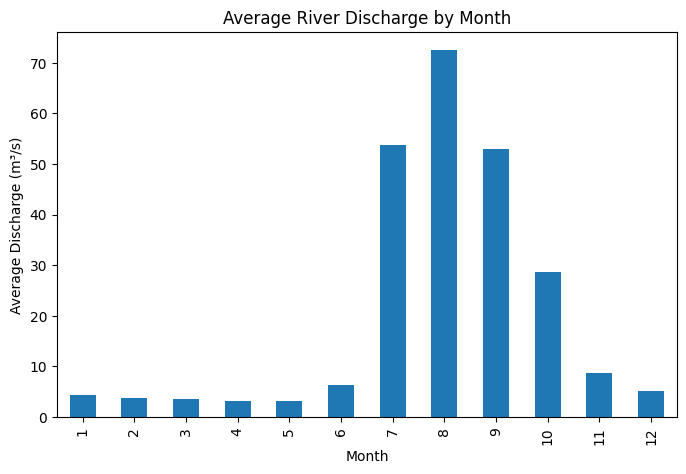

In [ ]:
df['date']=pd.to_datetime(df['date'])
df['month']=df['date'].dt.month


monthly_discharge = df.groupby("month")["river_discharge_m3s"].mean()

monthly_discharge.plot(kind="bar", figsize=(8, 5))
plt.title("Average River Discharge by Month")
plt.xlabel("Month")
plt.ylabel("Average Discharge (m³/s)")
plt.show()

In [ ]:
df.nlargest(10, "river_discharge_m3s")[
    ["date", "location", "river_discharge_m3s"]
]

,date,location,river_discharge_m3s
6368,2024-09-28,Kusum,3175.87
6378,2024-09-29,Kusum,2359.48
2374,2023-07-04,Kusum,1802.02
5538,2024-07-07,Kusum,1736.80
5528,2024-07-06,Kusum,1609.65
2371,2023-07-01,Kusum,1421.33
5548,2024-07-08,Kusum,1418.06
9568,2025-08-14,Kusum,1190.24
2375,2023-07-05,Kusum,1182.04
9478,2025-08-05,Kusum,1173.90


In [ ]:
df = df.sort_values(["location", "date"])

In [ ]:
df["rain_lag1"] = df.groupby("location")["rain_mm"].shift(1)
df["rain_lag2"] = df.groupby("location")["rain_mm"].shift(2)
df["rain_lag3"] = df.groupby("location")["rain_mm"].shift(3)

df.head(10)

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,...,precipitation_hours,relative_humidity_mean_pct,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s,month,rain_lag1,rain_lag2,rain_lag3
365,2023-01-01,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.291,...,0,71,7.8,24.1,106,1.05,1,NaN,NaN,NaN
366,2023-01-02,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.303,...,0,73,7.3,25.2,80,1.05,1,0.0,NaN,NaN
367,2023-01-03,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.306,...,0,65,7.9,24.1,89,1.01,1,0.0,0.0,NaN
368,2023-01-04,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,0,61,8.0,22.3,77,0.99,1,0.0,0.0,0.0
369,2023-01-05,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,0,55,5.9,21.6,67,0.97,1,0.0,0.0,0.0
370,2023-01-06,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.310,...,0,43,5.5,23.0,92,0.95,1,0.0,0.0,0.0
371,2023-01-07,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.305,...,0,44,7.1,21.6,85,0.94,1,0.0,0.0,0.0
372,2023-01-08,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.299,...,0,45,6.0,20.2,85,0.94,1,0.0,0.0,0.0
373,2023-01-09,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.297,...,0,48,7.8,24.5,83,0.92,1,0.0,0.0,0.0
374,2023-01-10,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.296,...,0,48,6.4,20.5,75,0.92,1,0.0,0.0,0.0


In [ ]:
df["rain_3day_total"] = df.groupby("location")["rain_mm"].transform(
    lambda x: x.shift(1).rolling(3).sum()
)

df["rain_7day_avg"] = df.groupby("location")["rain_mm"].transform(
    lambda x: x.shift(1).rolling(7).mean()
)


df.head(10)

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,...,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s,month,rain_lag1,rain_lag2,rain_lag3,rain_3day_total,rain_7day_avg
365,2023-01-01,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.291,...,7.8,24.1,106,1.05,1,NaN,NaN,NaN,NaN,NaN
366,2023-01-02,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.303,...,7.3,25.2,80,1.05,1,0.0,NaN,NaN,NaN,NaN
367,2023-01-03,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.306,...,7.9,24.1,89,1.01,1,0.0,0.0,NaN,NaN,NaN
368,2023-01-04,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,8.0,22.3,77,0.99,1,0.0,0.0,0.0,0.0,NaN
369,2023-01-05,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,5.9,21.6,67,0.97,1,0.0,0.0,0.0,0.0,NaN
370,2023-01-06,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.310,...,5.5,23.0,92,0.95,1,0.0,0.0,0.0,0.0,NaN
371,2023-01-07,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.305,...,7.1,21.6,85,0.94,1,0.0,0.0,0.0,0.0,NaN
372,2023-01-08,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.299,...,6.0,20.2,85,0.94,1,0.0,0.0,0.0,0.0,0.0
373,2023-01-09,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.297,...,7.8,24.5,83,0.92,1,0.0,0.0,0.0,0.0,0.0
374,2023-01-10,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.296,...,6.4,20.5,75,0.92,1,0.0,0.0,0.0,0.0,0.0


In [ ]:
df["discharge_lag1"] = df.groupby("location")["river_discharge_m3s"].shift(1)
df.head(10)

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,...,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s,month,rain_lag1,rain_lag2,rain_lag3,rain_3day_total,rain_7day_avg,discharge_lag1
365,2023-01-01,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.291,...,24.1,106,1.05,1,NaN,NaN,NaN,NaN,NaN,NaN
366,2023-01-02,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.303,...,25.2,80,1.05,1,0.0,NaN,NaN,NaN,NaN,1.05
367,2023-01-03,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.306,...,24.1,89,1.01,1,0.0,0.0,NaN,NaN,NaN,1.05
368,2023-01-04,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,22.3,77,0.99,1,0.0,0.0,0.0,0.0,NaN,1.01
369,2023-01-05,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.308,...,21.6,67,0.97,1,0.0,0.0,0.0,0.0,NaN,0.99
370,2023-01-06,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.310,...,23.0,92,0.95,1,0.0,0.0,0.0,0.0,NaN,0.97
371,2023-01-07,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.305,...,21.6,85,0.94,1,0.0,0.0,0.0,0.0,NaN,0.95
372,2023-01-08,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.299,...,20.2,85,0.94,1,0.0,0.0,0.0,0.0,0.0,0.94
373,2023-01-09,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.297,...,24.5,83,0.92,1,0.0,0.0,0.0,0.0,0.0,0.94
374,2023-01-10,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.0,0.296,...,20.5,75,0.92,1,0.0,0.0,0.0,0.0,0.0,0.92


In [ ]:
df["next_day_discharge"] = df.groupby("location")["river_discharge_m3s"].shift(-1)

df[["date", "location", "river_discharge_m3s", "discharge_lag1", "next_day_discharge"]].head(10)

,date,location,river_discharge_m3s,discharge_lag1,next_day_discharge
365,2023-01-01,Bahrabise,1.05,NaN,1.05
366,2023-01-02,Bahrabise,1.05,1.05,1.01
367,2023-01-03,Bahrabise,1.01,1.05,0.99
368,2023-01-04,Bahrabise,0.99,1.01,0.97
369,2023-01-05,Bahrabise,0.97,0.99,0.95
370,2023-01-06,Bahrabise,0.95,0.97,0.94
371,2023-01-07,Bahrabise,0.94,0.95,0.94
372,2023-01-08,Bahrabise,0.94,0.94,0.92
373,2023-01-09,Bahrabise,0.92,0.94,0.92
374,2023-01-10,Bahrabise,0.92,0.92,0.91


In [ ]:
df["year"] = df["date"].dt.year
df["day_of_week"] = df["date"].dt.dayofweek

df[["date", "year", "month", "day_of_week"]].head()

,date,year,month,day_of_week
365,2023-01-01,2023,1,6
366,2023-01-02,2023,1,0
367,2023-01-03,2023,1,1
368,2023-01-04,2023,1,2
369,2023-01-05,2023,1,3


In [ ]:
df.isnull().sum()

,0
date,0
location,0
river,0
basin,0
dhm_station,0
latitude,0
longitude,0
elevation_m,0
precipitation_mm,0
soil_moisture_0_100cm_m3m3,0


In [ ]:
df = df.dropna().copy()

print("Dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Dataset shape: (13310, 29)
Remaining missing values: 0


In [ ]:
X = df.drop(columns=["next_day_discharge","date","dhm_station"])

y = df["next_day_discharge"]

In [ ]:
print(X.select_dtypes(include="object").columns.tolist())

['location', 'river', 'basin']


In [ ]:
X = pd.get_dummies(
    X,
    columns=["location", "river", "basin"],
    dtype=int
)

In [ ]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Text columns remaining:", X.select_dtypes(include="object").columns.tolist())

Features shape: (13310, 51)
Target shape: (13310,)
Text columns remaining: []


In [ ]:
df = df.sort_values("date")

dates = sorted(df["date"].unique())

split_index = int(len(dates) * 0.8)
split_date = dates[split_index]


train_idx = df.index[df["date"].isin(dates[:split_index])]
test_idx = df.index[df["date"].isin(dates[split_index:])]

X_train = X.loc[train_idx]
X_test = X.loc[test_idx]

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

print("Split date:", split_date)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Split date: 2025-12-07 00:00:00
Training features: (10640, 51)
Testing features: (2670, 51)
Training target: (10640,)
Testing target: (2670,)


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


y_pred_base = X_test["river_discharge_m3s"]

mae_base  = mean_absolute_error(y_test, y_pred_base)
mse_base  = mean_squared_error(y_test, y_pred_base)
rmse_base = np.sqrt(mse_base)
r2_base   = r2_score(y_test, y_pred_base)

print("Baseline MAE :", mae_base)
print("Baseline MSE :", mse_base)
print("Baseline RMSE:", rmse_base)
print("Baseline R²  :", r2_base)

Baseline MAE : 1.9716666666666665
Baseline MSE : 202.44691097378274
Baseline RMSE: 14.228383990242277
Baseline R²  : 0.9415281395562378


In [ ]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()

model_lr.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred_lr = np.clip(model_lr.predict(X_test), 0, None)

print("Predicted discharge:", y_pred_lr[:10])
print("Actual discharge:", y_test.iloc[:10].values)

Predicted discharge: [ 0.          0.          0.         20.25907945  0.         21.19204419
 38.60520132  0.          0.          0.        ]
Actual discharge: [ 1.05  0.22  0.   19.75  0.37 23.43 17.2   1.7   0.31  0.34]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression MAE:", mae_lr)
print("Linear Regression MSE:", mse_lr)
print("Linear Regression RMSE:", rmse_lr)
print("Linear Regression R² Score:", r2_lr)

Linear Regression MAE: 6.221238093389746
Linear Regression MSE: 267.502045618901
Linear Regression RMSE: 16.355489770071117
Linear Regression R² Score: 0.9227385480735991


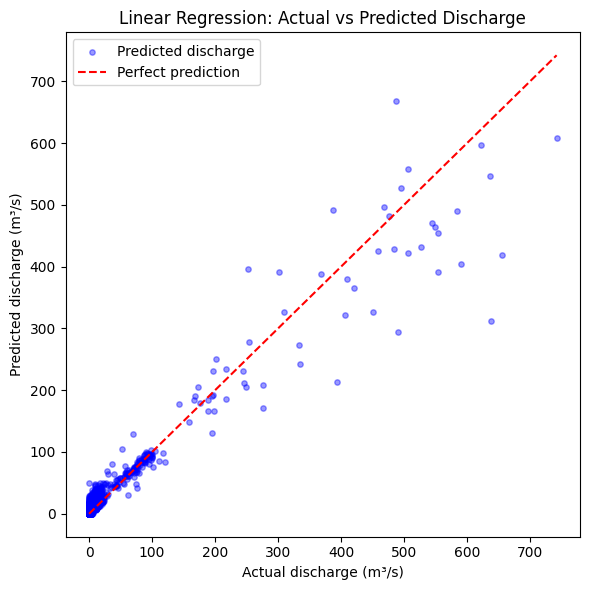

In [ ]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test, y_pred_lr,
    color="blue",
    alpha=0.4,
    s=15,
    label="Predicted discharge"
)

max_val = max(y_test.max(), y_pred_lr.max())

plt.plot(
    [0, max_val], [0, max_val],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.title("Linear Regression: Actual vs Predicted Discharge")
plt.xlabel("Actual discharge (m³/s)")
plt.ylabel("Predicted discharge (m³/s)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeRegressor

model_dt = DecisionTreeRegressor(random_state=42)

model_dt.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [ ]:
y_pred_dt = model_dt.predict(X_test)

print("Predicted discharge:", y_pred_dt[:10])
print("Actual discharge:", y_test.iloc[:10].values)

Predicted discharge: [ 1.04  0.2   0.   19.65  0.38 23.15 16.82  1.75  0.29  0.33]
Actual discharge: [ 1.05  0.22  0.   19.75  0.37 23.43 17.2   1.7   0.31  0.34]


In [ ]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree MAE:", mae_dt)
print("Decision Tree MSE:", mse_dt)
print("Decision Tree RMSE:", rmse_dt)
print("Decision Tree R² Score:", r2_dt)

Decision Tree MAE: 3.2169588014981274
Decision Tree MSE: 583.8315181273408
Decision Tree RMSE: 24.162605780986055
Decision Tree R² Score: 0.8313744828883433


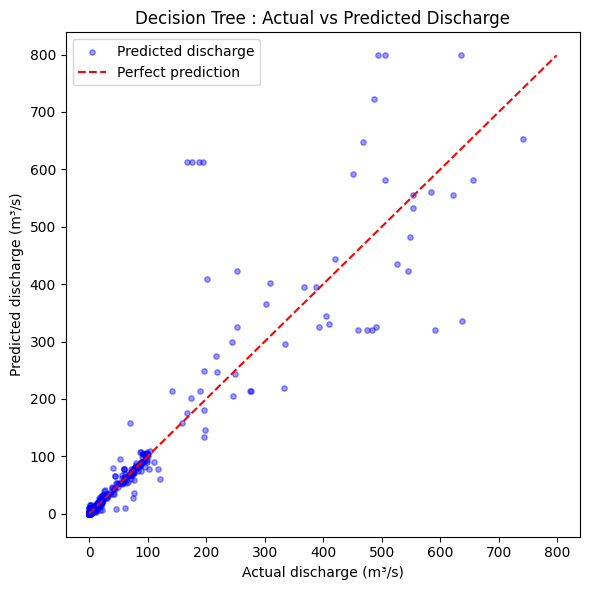

In [ ]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test, y_pred_dt,
    color="blue",
    alpha=0.4,
    s=15,
    label="Predicted discharge"
)

max_val = max(y_test.max(), y_pred_dt.max())

plt.plot(
    [0, max_val], [0, max_val],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.title("Decision Tree : Actual vs Predicted Discharge")
plt.xlabel("Actual discharge (m³/s)")
plt.ylabel("Predicted discharge (m³/s)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [ ]:
y_pred_rf = model_rf.predict(X_test)

print("Predicted discharge:", y_pred_rf[:10])
print("Actual discharge:", y_test.iloc[:10].values)

Predicted discharge: [ 1.0362  0.2157  0.     19.7594  0.385  23.295  17.1713  1.7216  0.3039
  0.3338]
Actual discharge: [ 1.05  0.22  0.   19.75  0.37 23.43 17.2   1.7   0.31  0.34]


In [ ]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest MAE:", mae_rf)
print("Random Forest MSE:", mse_rf)
print("Random Forest RMSE:", rmse_rf)
print("Random Forest R² Score:", r2_rf)

Random Forest MAE: 2.4945138951310866
Random Forest MSE: 302.4759182308504
Random Forest RMSE: 17.391834814959875
Random Forest R² Score: 0.9126371966194955


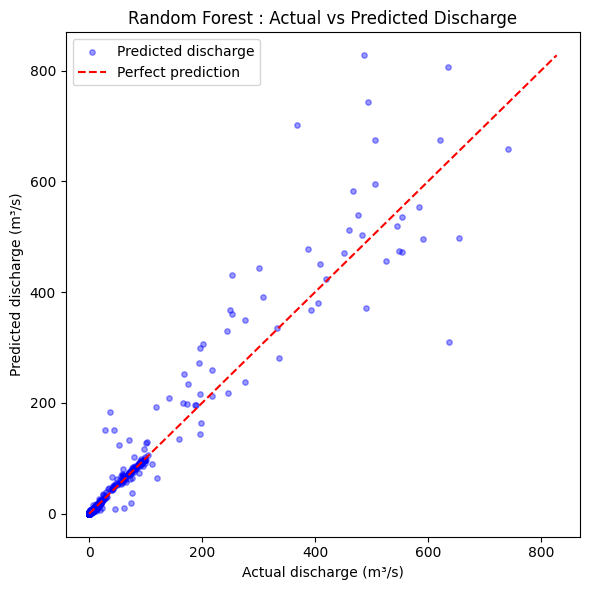

In [ ]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test, y_pred_rf,
    color="blue",
    alpha=0.4,
    s=15,
    label="Predicted discharge"
)

max_val = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [0, max_val], [0, max_val],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.title("Random Forest : Actual vs Predicted Discharge")
plt.xlabel("Actual discharge (m³/s)")
plt.ylabel("Predicted discharge (m³/s)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": ["Baseline (tomorrow = today)", "Linear Regression", "Decision Tree", "Random Forest"],
    "MAE":  [mae_base, mae_lr, mae_dt, mae_rf],
    "MSE":  [mse_base, mse_lr, mse_dt, mse_rf],
    "RMSE": [rmse_base, rmse_lr, rmse_dt, rmse_rf],
    "R² Score": [r2_base, r2_lr, r2_dt, r2_rf],
})
print(results.round(3))

                         Model    MAE      MSE    RMSE  R² Score
0  Baseline (tomorrow = today)  1.972  202.447  14.228     0.942
1            Linear Regression  6.221  267.502  16.355     0.923
2                Decision Tree  3.217  583.832  24.163     0.831
3                Random Forest  2.495  302.476  17.392     0.913


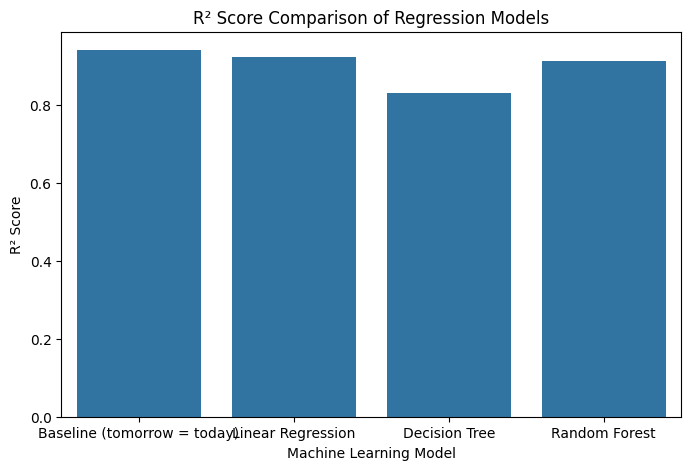

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(data=results, x="Model", y="R² Score")

plt.title("R² Score Comparison of Regression Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")
plt.show()

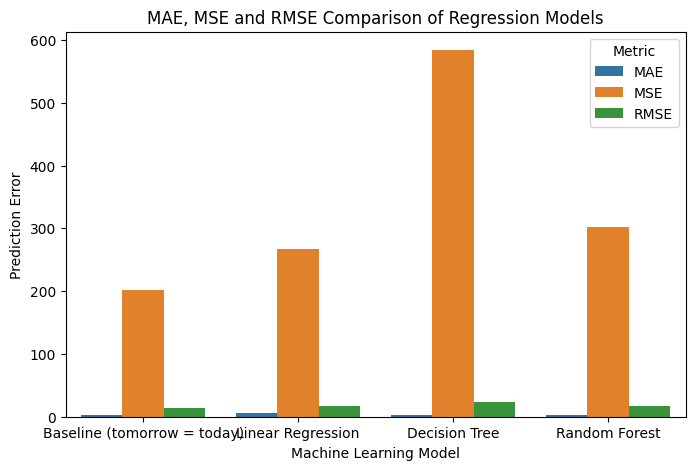

In [ ]:
results_melted = results.melt(
    id_vars="Model",
    value_vars=["MAE", "MSE", "RMSE"],
    var_name="Metric",
    value_name="Error"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Error",
    hue="Metric"
)

plt.title("MAE, MSE and RMSE Comparison of Regression Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Prediction Error")
plt.show()

In [ ]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(10))

                       Feature  Importance
13         river_discharge_m3s    0.822864
5                      rain_mm    0.028599
6           temperature_mean_c    0.026698
3             precipitation_mm    0.024488
7             dew_point_mean_c    0.018159
15                   rain_lag1    0.011974
8          precipitation_hours    0.011267
4   soil_moisture_0_100cm_m3m3    0.008879
20              discharge_lag1    0.007642
11          wind_gusts_max_kmh    0.005904


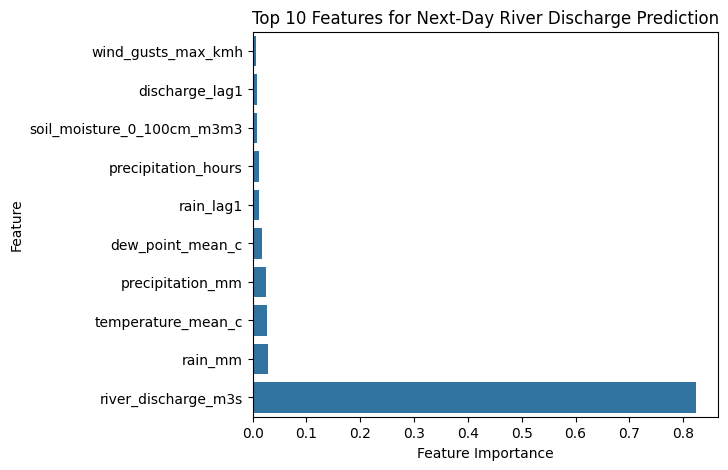

In [ ]:
top_features = importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(6, 5))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features for Next-Day River Discharge Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

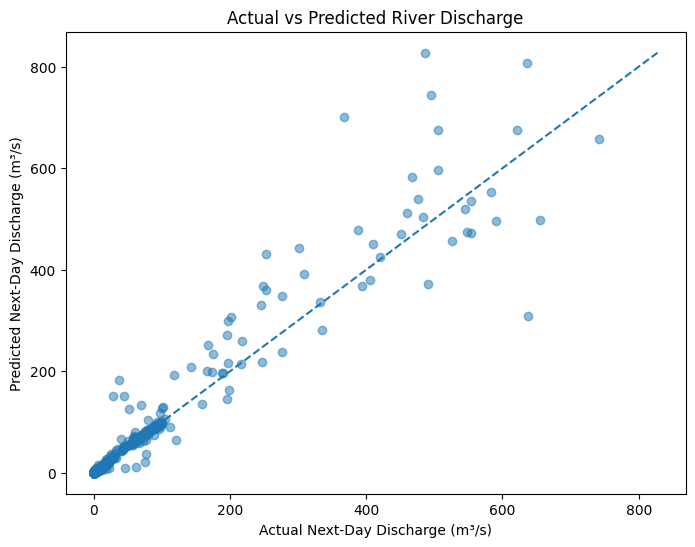

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_rf, alpha=0.5)

# Reference line: perfect predictions
min_value = min(y_test.min(), y_pred_rf.min())
max_value = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted River Discharge")
plt.xlabel("Actual Next-Day Discharge (m³/s)")
plt.ylabel("Predicted Next-Day Discharge (m³/s)")
plt.show()

In [ ]:
comparison = pd.DataFrame({
    "Actual_Discharge": y_test,
    "Predicted_Discharge": y_pred_rf
})

comparison["Absolute_Error"] = abs(
    comparison["Actual_Discharge"] -
    comparison["Predicted_Discharge"]
)

top_10 = comparison.sort_values(
    by="Actual_Discharge",
    ascending=False
).head(10)

print(top_10.round(2))

       Actual_Discharge  Predicted_Discharge  Absolute_Error
12958            742.02               658.23           83.79
13368            655.15               497.15          158.00
12948            637.26               309.25          328.01
13318            635.80               806.57          170.77
13378            621.30               674.80           53.50
13308            590.56               495.03           95.53
13268            583.79               553.33           30.46
13258            553.63               535.19           18.44
13178            553.63               473.23           80.40
13138            548.54               475.11           73.43


In [ ]:
top_10_mae = top_10["Absolute_Error"].mean()

print("Top 10 High-Discharge MAE:", round(top_10_mae, 2), "m³/s")
print("Overall Test MAE:", round(mae_rf, 2), "m³/s")

Top 10 High-Discharge MAE: 109.23 m³/s
Overall Test MAE: 2.49 m³/s


In [ ]:
print("Test observations:", len(y_test))
print("Predictions:", len(y_pred_rf))

print("Recalculated MAE:", mean_absolute_error(y_test, y_pred_rf))

print("Recalculated MSE:", mean_squared_error(y_test, y_pred_rf))

print("Recalculated RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))

print("Recalculated R²:", r2_score(y_test, y_pred_rf))

Test observations: 2670
Predictions: 2670
Recalculated MAE: 2.4945138951310866
Recalculated MSE: 302.4759182308504
Recalculated RMSE: 17.391834814959875
Recalculated R²: 0.9126371966194955


In [ ]:
comparison_check = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_rf
})

comparison_check["Absolute_Error"] = (
    comparison_check["Actual"] - comparison_check["Predicted"]
).abs()

print("Overall MAE:", comparison_check["Absolute_Error"].mean())

print("\nTop 10 actual discharge values:")
print(
    comparison_check
    .nlargest(10, "Actual")[
        ["Actual", "Predicted", "Absolute_Error"]
    ].round(2)
)

print(
    "\nTop 10 MAE:",
    comparison_check.nlargest(10, "Actual")["Absolute_Error"].mean().round(2)
)

Overall MAE: 2.4945138951310866

Top 10 actual discharge values:
       Actual  Predicted  Absolute_Error
12958  742.02     658.23           83.79
13368  655.15     497.15          158.00
12948  637.26     309.25          328.01
13318  635.80     806.57          170.77
13378  621.30     674.80           53.50
13308  590.56     495.03           95.53
13268  583.79     553.33           30.46
13178  553.63     473.23           80.40
13258  553.63     535.19           18.44
13138  548.54     475.11           73.43

Top 10 MAE: 109.23


In [ ]:
errors = comparison_check["Absolute_Error"]

print("Mean Absolute Error:", round(errors.mean(), 2))
print("Median Absolute Error:", round(errors.median(), 2))
print("90th Percentile Error:", round(errors.quantile(0.90), 2))
print("Maximum Absolute Error:", round(errors.max(), 2))


Mean Absolute Error: 2.49
Median Absolute Error: 0.05
90th Percentile Error: 1.47
Maximum Absolute Error: 341.01


In [ ]:
print(comparison_check["Absolute_Error"].describe())

print(
    comparison_check.nlargest(10, "Absolute_Error")[
        ["Actual", "Predicted", "Absolute_Error"]
    ].round(2)
)

count    2670.000000
mean        2.494514
std        17.215235
min         0.000000
25%         0.008400
50%         0.046850
75%         0.258850
max       341.005800
Name: Absolute_Error, dtype: float64
       Actual  Predicted  Absolute_Error
12968  486.53     827.54          341.01
13228  367.98     701.67          333.69
12948  637.26     309.25          328.01
13278  494.45     744.01          249.56
13198  252.51     430.59          178.08
13318  635.80     806.57          170.77
13328  505.99     674.95          168.96
13368  655.15     497.15          158.00
12608   37.11     182.81          145.70
12978  301.69     443.32          141.63


In [ ]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits=5)
cv_scores = cross_val_score(
    model_rf, X_train, y_train,
    cv=tscv, scoring="neg_mean_absolute_error"
)
print("Random Forest CV MAE:", -cv_scores.mean())

Random Forest CV MAE: 27.710541838691483


In [ ]:
# Predict the CHANGE from today's discharge, then add it back
y_delta = df["next_day_discharge"] - df["river_discharge_m3s"]

model_rf_delta = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model_rf_delta.fit(X_train, y_delta.loc[train_idx])

y_pred_delta = np.clip(
    X_test["river_discharge_m3s"] + model_rf_delta.predict(X_test), 0, None
)

mae_delta = mean_absolute_error(y_test, y_pred_delta)
rmse_delta = np.sqrt(mean_squared_error(y_test, y_pred_delta))
r2_delta = r2_score(y_test, y_pred_delta)

print("RF (change-from-today) MAE :", mae_delta)
print("RF (change-from-today) RMSE:", rmse_delta)
print("RF (change-from-today) R²  :", r2_delta)
print("Baseline MAE for comparison:", mae_base)

RF (change-from-today) MAE : 2.556888913857678
RF (change-from-today) RMSE: 17.52914647168553
RF (change-from-today) R²  : 0.911252260940024
Baseline MAE for comparison: 1.9716666666666665


## Part 2: Weather Classification

Next, we predict tomorrow's weather class (Cold, Cool, Warm or Hot) from today's weather data.

In [ ]:
train_df = df.loc[train_idx]

cutoffs = train_df.groupby("location")["temperature_mean_c"].quantile([0.25, 0.5, 0.75]).unstack()
cutoffs.columns = ["q25", "q50", "q75"]
cutoffs.round(1)

,q25,q50,q75
location,,,
Bahrabise,16.0,21.6,24.9
Belsot,21.1,26.3,28.8
Bhada Bridge,19.2,26.3,28.9
Chameliya/Nayalbadi,16.2,22.9,26.3
Chatara,20.6,25.6,27.5
Chisapani,18.0,24.9,28.0
Devghat,19.5,25.0,27.9
Khokana,14.9,19.9,22.9
Kusum,19.5,26.1,28.8


In [ ]:
t   = df["temperature_mean_c"]
q25 = df["location"].map(cutoffs["q25"])
q50 = df["location"].map(cutoffs["q50"])
q75 = df["location"].map(cutoffs["q75"])

df["weather_class"] = np.select(
    [t <= q25, t <= q50, t <= q75],
    ["Cold", "Cool", "Warm"],
    default="Hot"
)

print(df["weather_class"].value_counts())
df[["date", "location", "temperature_mean_c", "weather_class"]].head(10)

weather_class
Cold    3476
Hot     3373
Cool    3255
Warm    3206
Name: count, dtype: int64


,date,location,temperature_mean_c,weather_class
372,2023-01-08,Bahrabise,12.8,Cold
3292,2023-01-08,Chameliya/Nayalbadi,13.4,Cold
1467,2023-01-08,Chatara,14.1,Cold
1832,2023-01-08,Belsot,11.1,Cold
2927,2023-01-08,Chisapani,10.9,Cold
1102,2023-01-08,Devghat,12.1,Cold
737,2023-01-08,Khokana,12.6,Cold
2197,2023-01-08,Kusum,11.7,Cold
7,2023-01-08,Rasuwagadhi,12.7,Cold
2562,2023-01-08,Bhada Bridge,9.9,Cold


In [ ]:
df = df.sort_values(["location", "date"])

df["next_day_weather"] = df.groupby("location")["weather_class"].shift(-1)

df["temp_lag1"] = df.groupby("location")["temperature_mean_c"].shift(1)
df["temp_3day_avg"] = df.groupby("location")["temperature_mean_c"].transform(
    lambda x: x.shift(1).rolling(3).mean()
)

df[["date", "location", "temperature_mean_c", "weather_class", "next_day_weather", "temp_lag1", "temp_3day_avg"]].head(10)

,date,location,temperature_mean_c,weather_class,next_day_weather,temp_lag1,temp_3day_avg
372,2023-01-08,Bahrabise,12.8,Cold,Cold,NaN,NaN
373,2023-01-09,Bahrabise,12.9,Cold,Cold,12.8,NaN
374,2023-01-10,Bahrabise,13.5,Cold,Cold,12.9,NaN
375,2023-01-11,Bahrabise,12.3,Cold,Cold,13.5,13.066667
376,2023-01-12,Bahrabise,12.7,Cold,Cold,12.3,12.900000
377,2023-01-13,Bahrabise,12.9,Cold,Cold,12.7,12.833333
378,2023-01-14,Bahrabise,12.4,Cold,Cold,12.9,12.633333
379,2023-01-15,Bahrabise,12.2,Cold,Cold,12.4,12.666667
380,2023-01-16,Bahrabise,11.9,Cold,Cold,12.2,12.500000
381,2023-01-17,Bahrabise,10.7,Cold,Cold,11.9,12.166667


In [ ]:
X_cls = X.copy()
X_cls["temp_lag1"] = df["temp_lag1"]
X_cls["temp_3day_avg"] = df["temp_3day_avg"]

valid = df["next_day_weather"].notna() & df["temp_lag1"].notna() & df["temp_3day_avg"].notna()

train_c = train_idx[valid.loc[train_idx].values]
test_c  = test_idx[valid.loc[test_idx].values]

X_train_c, X_test_c = X_cls.loc[train_c], X_cls.loc[test_c]
y_train_c, y_test_c = df.loc[train_c, "next_day_weather"], df.loc[test_c, "next_day_weather"]

print("Training rows:", X_train_c.shape[0])
print("Testing rows :", X_test_c.shape[0])

Training rows: 10610
Testing rows : 2660


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

In [ ]:
# Baseline: tomorrow's class = today's class
y_pred_base_c = df.loc[test_c, "weather_class"]

# Logistic Regression
model_log = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model_log.fit(X_train_c, y_train_c)
y_pred_log = model_log.predict(X_test_c)

# Decision Tree
model_dtc = DecisionTreeClassifier(max_depth=8, random_state=42)
model_dtc.fit(X_train_c, y_train_c)
y_pred_dtc = model_dtc.predict(X_test_c)

# Random Forest
model_rfc = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model_rfc.fit(X_train_c, y_train_c)
y_pred_rfc = model_rfc.predict(X_test_c)

print("Models trained")

Models trained


In [ ]:
preds = {
    "Baseline (tomorrow = today)": y_pred_base_c,
    "Logistic Regression": y_pred_log,
    "Decision Tree": y_pred_dtc,
    "Random Forest": y_pred_rfc,
}

results_c = pd.DataFrame({
    "Model": list(preds.keys()),
    "Accuracy": [accuracy_score(y_test_c, p) for p in preds.values()],
    "F1 (macro)": [f1_score(y_test_c, p, average="macro") for p in preds.values()],
})
print(results_c.round(3))

                         Model  Accuracy  F1 (macro)
0  Baseline (tomorrow = today)     0.850       0.834
1          Logistic Regression     0.843       0.831
2                Decision Tree     0.798       0.781
3                Random Forest     0.824       0.810


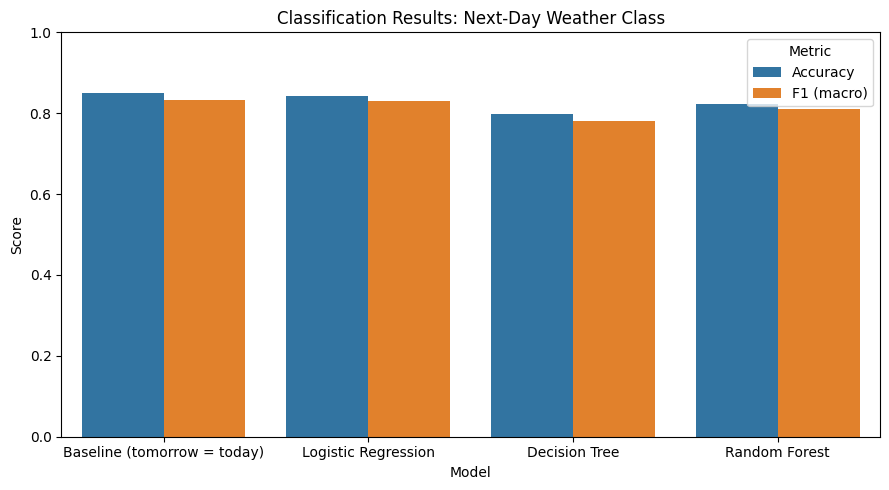

In [ ]:
results_melted_c = results_c.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(9, 5))
sns.barplot(data=results_melted_c, x="Model", y="Score", hue="Metric")
plt.title("Classification Results: Next-Day Weather Class")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Best classifier: Logistic Regression


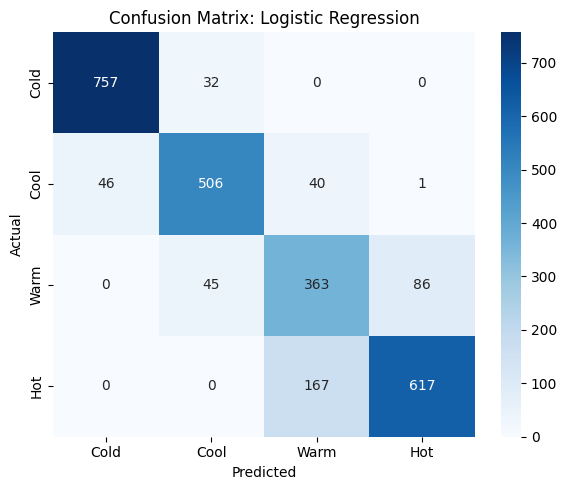

              precision    recall  f1-score   support

        Cold       0.94      0.96      0.95       789
        Cool       0.87      0.85      0.86       593
        Warm       0.64      0.73      0.68       494
         Hot       0.88      0.79      0.83       784

    accuracy                           0.84      2660
   macro avg       0.83      0.83      0.83      2660
weighted avg       0.85      0.84      0.85      2660



In [ ]:
best_name = results_c.iloc[1:].sort_values("F1 (macro)", ascending=False).iloc[0]["Model"]
best_pred = preds[best_name]
print("Best classifier:", best_name)

labels = ["Cold", "Cool", "Warm", "Hot"]
cm = confusion_matrix(y_test_c, best_pred, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix: " + best_name)
plt.tight_layout()
plt.show()

print(classification_report(y_test_c, best_pred, labels=labels))

In [ ]:
latest = df.groupby("location").tail(1).index

forecast = pd.DataFrame({
    "Station": df.loc[latest, "location"],
    "Latest date": df.loc[latest, "date"].dt.date,
    "Temperature (°C)": df.loc[latest, "temperature_mean_c"],
    "Today's class": df.loc[latest, "weather_class"],
    "Predicted tomorrow": model_log.predict(X_cls.loc[latest]),
}).reset_index(drop=True)

forecast

,Station,Latest date,Temperature (°C),Today's class,Predicted tomorrow
0,Bahrabise,2026-08-30,25.6,Hot,Hot
1,Belsot,2026-08-30,29.7,Hot,Hot
2,Bhada Bridge,2026-08-30,27.4,Warm,Warm
3,Chameliya/Nayalbadi,2026-08-30,26.0,Warm,Warm
4,Chatara,2026-08-30,28.5,Hot,Hot
5,Chisapani,2026-08-30,27.5,Warm,Warm
6,Devghat,2026-08-30,29.9,Hot,Hot
7,Khokana,2026-08-30,23.6,Hot,Hot
8,Kusum,2026-08-30,27.8,Warm,Warm
9,Rasuwagadhi,2026-08-30,24.3,Hot,Hot


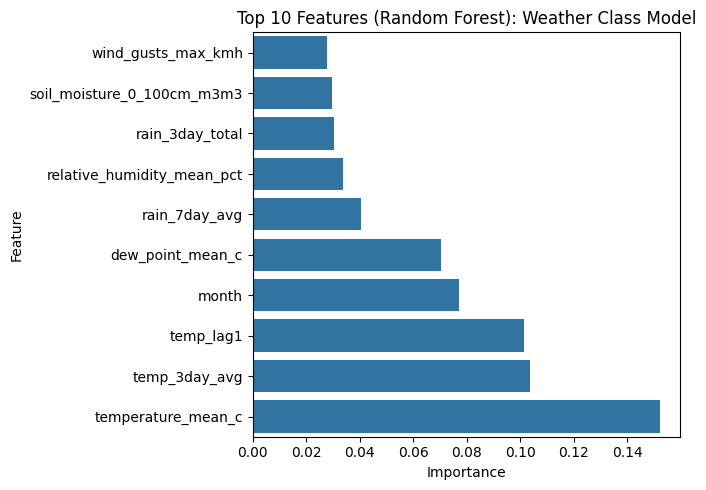

In [ ]:
importance_c = pd.DataFrame({
    "Feature": X_train_c.columns,
    "Importance": model_rfc.feature_importances_
}).sort_values("Importance", ascending=False).head(10)

plt.figure(figsize=(7, 5))
sns.barplot(data=importance_c.sort_values("Importance"), x="Importance", y="Feature")
plt.title("Top 10 Features (Random Forest): Weather Class Model")
plt.tight_layout()
plt.show()


## Conclusion

This project used Nepal's flood and weather data to predict two things for the next day: river discharge (a number) and weather class (Cold, Cool, Warm or Hot).

**River discharge.** Random Forest was the best of the three models, with the lowest MAE (2.49 m³/s) and an R² of 0.913. However, the simple baseline "tomorrow = today" scored slightly better (MAE 1.97 m³/s, R² 0.942), and predicting the change from today did not improve on it. Today's discharge was by far the most important input (about 82% of the Random Forest's importance). The largest errors happened on extreme flood days.

**Weather class.** Each day was labelled by comparing its temperature with its own station's normal. Logistic Regression was the best of the three models (accuracy 84.3%, F1 0.831), followed by Random Forest and Decision Tree, but the simple baseline "tomorrow = today"  was again slightly better (accuracy 85.0%). The model was best on Cold days and weakest on Warm days, and its mistakes were only between neighbouring classes. Today's temperature and the recent temperature trend were the most important inputs. For the latest day, the model predicted that all 10 stations stay in their current weather class.

**Overall.** In both parts, tomorrow is very similar to today, so the simple baseline is hard to beat. The models still show which factors matter most. More years of data and better flood-peak prediction are the main areas for improvement.